# Day 9: Image Matching
Today we will cover:
- Feature Descriptors
- FLANN Matching

## Why Image Matching?
Image matching allows us to identify and compare visual patterns across different images. It is widely used in logo detection, object recognition, and image retrieval.

## Feature Descriptors
Feature descriptors encode local image patches around keypoints into numerical vectors.
- Examples: SIFT, ORB, SURF.
- They allow comparison of features across images.

## FLANN (Fast Library for Approximate Nearest Neighbors)
FLANN is an efficient algorithm for matching feature descriptors.
- Pros: Fast, scalable.
- Cons: Approximate, may require parameter tuning.

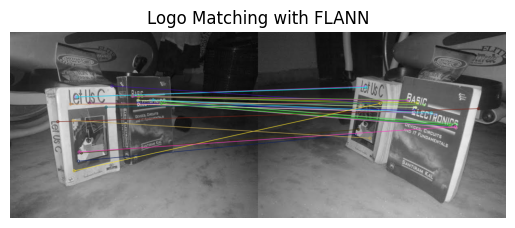

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load two images (logo and scene)
logo = cv2.imread('left.jpg', cv2.IMREAD_GRAYSCALE)
scene = cv2.imread('right.jpg', cv2.IMREAD_GRAYSCALE)

# Initialize ORB detector
orb = cv2.ORB_create()
kp1, des1 = orb.detectAndCompute(logo, None)
kp2, des2 = orb.detectAndCompute(scene, None)

# FLANN parameters for ORB (using LSH index)
FLANN_INDEX_LSH = 6
index_params = dict(algorithm=FLANN_INDEX_LSH,
                   table_number=6,
                   key_size=12,
                   multi_probe_level=1)
search_params = dict(checks=50)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

# Apply Lowe's ratio test
good = []
for m,n in matches:
    if m.distance < 0.7*n.distance:
        good.append(m)

img_matches = cv2.drawMatches(logo, kp1, scene, kp2, good, None, flags=2)
plt.imshow(img_matches)
plt.title("Logo Matching with FLANN")
plt.axis('off')
plt.show()

## Exercise: Match Logos Across Images
Try replacing `logo.jpg` and `scene.jpg` with different logos and scenes. Observe how many matches are found and how accurate they are.

## Mini Project: Logo Detector
We will detect a logo in a scene using feature matching and homography.

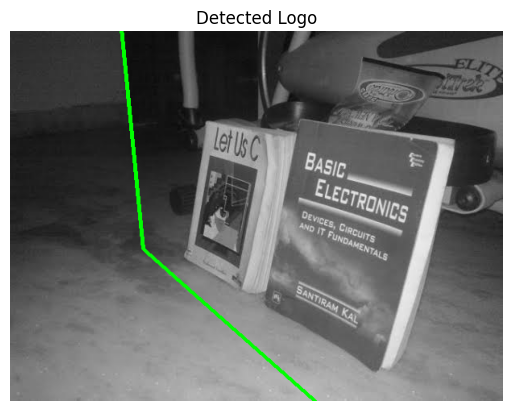

In [2]:
# Extract matched keypoints
if len(good) > 10:
    src_pts = np.float32([ kp1[m.queryIdx].pt for m in good ]).reshape(-1,1,2)
    dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good ]).reshape(-1,1,2)

    # Find homography
    M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    h, w = logo.shape
    pts = np.float32([[0,0],[0,h-1],[w-1,h-1],[w-1,0]]).reshape(-1,1,2)
    dst = cv2.perspectiveTransform(pts, M)

    scene_color = cv2.cvtColor(scene, cv2.COLOR_GRAY2BGR)
    cv2.polylines(scene_color, [np.int32(dst)], True, (0,255,0), 3)

    plt.imshow(scene_color)
    plt.title("Detected Logo")
    plt.axis('off')
    plt.show()
else:
    print("Not enough matches found - try another image or adjust parameters.")